# 07B — ข้อมูล MX เพิ่มเติม: ตรวจรับข้อมูลก่อนขยายการวิเคราะห์

## tl;dr
เล่มนี้ตอบว่า **ข้อมูลเพิ่มช่วยอะไรได้ และส่วนไหนนำมาใช้ต่อได้แล้ว** อ่านตามลำดับจากช่วงเวลา → ข้อมูลซ้ำ → สถานะที่เทียบกันได้ → pressure และความสัมพันธ์ → แนวทางเข้า ML

มีข้อมูลหกเครื่อง ได้แก่ MX007, MX012, MX017, MX025, MX057 และ MX070 ผลด้านล่างคำนวณจากไฟล์รายวัน รวมไฟล์รายวันภายใน ZIP ของ MX057 ข้อมูลใหม่ถูกแปลงไว้เป็น Parquet แยกจากชุดเดิมแล้ว แต่ยังไม่มีการนำข้อมูลนี้ไปปรับโมเดลหรือ threshold

ผลตรวจวันที่ 9 กันยายน 2026: อ่าน 354 ไฟล์รายวัน รวม 29,819,668 แถว ได้ข้อมูลเพิ่มจริง 28,214,027 แถว แถวที่ซ้อนกับ primary 1,389,587 แถวตรงกันครบ 81 tags ส่วน 216,054 แถวที่เหลือเกี่ยวข้องกับ duplicate/conflicting timestamps ภายใน source และไม่ได้รวมเป็นข้อมูลใหม่

## Context & Methods
**จุดประสงค์:** ตรวจรับข้อมูลย้อนหลังสำหรับขยาย EDA, ตรวจ baseline drift และประเมินการใช้กับเครื่องที่ไม่อยู่ในชุดหลัก ผู้ใช้งานคือผู้ดูแลโครงการ ช่าง และผู้พัฒนาโมเดล

### Key Assumptions
- ต้นทางหนึ่งแถวเป็นหนึ่ง timestamp ของเครื่อง มี 8 โมดูล; output ระดับนาทีใช้ค่าจุดสุดท้ายของนาที พร้อมเวลา `available_at` จึงห้ามถือว่าค่านี้พร้อมใช้ตั้งแต่ต้นนาที
- Timezone ยังไม่ยืนยัน เก็บเวลาตามต้นทาง; วันที่จากชื่อไฟล์ต้องตรงกับวันที่ในเนื้อหา
- Pressure คงสเกลต้นทาง ไม่มีการคูณ/หารเพิ่มเติม; การเทียบข้อมูลวันซ้อนกันตรวจครบ 81 tags แต่ยังไม่ยืนยัน psig/psia
- Quality minute สำหรับ EDA ต้องมี 55–60 จุด, ช่องว่างภายในไม่เกิน 5 วินาที, ทุกจุดผ่าน Run/On/Busy=0/Valve≥0, SV คงที่ และไม่มี sentinel temperature ≤−199; ยังต้องผ่าน settling/service gate เพิ่มก่อน fit baseline
- ไม่มี confirmed fault labels; ช่วง 180–230 psi เป็น qualified field reference, ต่ำกว่า 180 เป็น undercharge screening และสูงกว่า 230 เป็น high-side investigation โดยไม่มีสิทธิ์ยืนยันสาเหตุ
- ไฟล์ Static, event fragments และ temporary copies อยู่ใน manifest แยก; ZIP อ่านสมาชิกทีละไฟล์พร้อม provenance; prepared windows เดิมไม่ได้นำมารวมเป็นข้อมูลใหม่
- ไม่มีการ fit model/scaler/HPO ในเล่มนี้ การแสดงข้อมูลย้อนหลังหลังเห็นผล outer test ถือเป็นการสำรวจเพื่อออกแบบการทดลองรุ่นถัดไป


### 1. ตั้งค่าตำแหน่งข้อมูล
บน Colab ให้ mount Drive และตั้ง `PROJECT_ROOT` ไปยังโฟลเดอร์โครงการที่มี outputs ถ้าจะอ่าน raw ใหม่ให้ตั้ง `EXTERNAL_ROOT`, `PRIMARY_ROOT` และ `REBUILD_RAW=True` เล่มนี้มีตัวนำเข้าฝังไว้ครบ จึงไม่ต้องหาไฟล์ support เพิ่ม

รอบส่งมอบรันการตรวจ raw ครบจากตัวนำเข้า และรัน Notebook จากผลที่ตรวจ checksum แล้ว การตั้งค่าเริ่มต้นช่วยเปิดกราฟซ้ำโดยไม่อ่าน raw หลาย GB ทุกครั้ง


In [1]:
from pathlib import Path
import sys, json, hashlib, importlib.util, subprocess
for package in ['polars', 'pandas', 'matplotlib', 'numpy', 'pyarrow']:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'notebooks').exists() and (PROJECT_ROOT.parent / 'notebooks').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
EXTERNAL_ROOT = Path(r'C:/Users/Book/OneDrive/เดสก์ท็อป/Data Analysis')  # Colab: change to mounted Drive
PRIMARY_ROOT = PROJECT_ROOT / 'HT9046MX-20260902T013607Z-1-001/HT9046MX/raw/table=ht9046mx_readings'
OUTPUT = PROJECT_ROOT / 'notebooks/outputs/ht9046mx_external_intake_v2'
REBUILD_RAW = False
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GOLD, INK = '#2878A5', '#C48C2D', '#30343B'


### 2. ตัวนำเข้าและการตรวจ checksum
ตัวนำเข้าด้านล่างอ่านต้นฉบับอย่างเดียว ผลตรวจและข้อมูลแปลงเขียนแยกไว้ใน OUTPUT

In [2]:
intake_namespace = {'__name__': 'external_intake_embedded'}
exec('"""Read-only source intake; write separate, auditable analysis partitions.\n\nNo fitting, threshold selection, automatic health labels or production activation.\nTime is retained as source-naive time. Source units are retained without scaling.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nimport re\nimport zipfile\nimport tempfile\nimport shutil\nfrom pathlib import Path\nimport polars as pl\n\nVERSION = "external_intake_v2"\nMIN_SAMPLES_PER_MINUTE = 55\nMAX_SAMPLES_PER_MINUTE = 60\nMAX_INTERNAL_GAP_SECONDS = 5\nFOLDERS = {"MX_007": "007", "MX017": "017", "MX057": "057", "MX070": "070",\n           "Clean Data MX12": "012", "Clean Data MX25": "025"}\nTAGS = ["Hp_1st", "Lp_1st", "Hp_2nd", "Lp_2nd", "Valve", "Status", "TempHi", "TempLo", "SV", "Busy"]\nCOLS = ["Status"] + [f"{tag}_{m}" for m in range(1, 9) for tag in TAGS]\nNUMERIC = [c for c in COLS if not c.startswith(("Status", "SV"))]\nNEW_MACHINES = {"007", "012", "025"}\n\n\ndef sources(root, folder):\n    """Materialize one ZIP member at a time under a disposable scratch path."""\n    for path in sorted((root / folder).rglob("*")):\n        if not path.is_file():\n            continue\n        source = path.relative_to(root).as_posix()\n        yield path, source, None\n        if path.suffix.lower() == \'.zip\':\n            with zipfile.ZipFile(path) as z:\n                for entry in z.infolist():\n                    if entry.is_dir():\n                        continue\n                    # Ignore internal directories for the temporary path; never extractall.\n                    name = Path(entry.filename.replace(\'\\\\\', \'/\')).name\n                    with tempfile.TemporaryDirectory(prefix=\'ht9046mx_zip_\') as temp:\n                        target = Path(temp) / name\n                        with z.open(entry) as src, target.open(\'wb\') as dst:\n                            shutil.copyfileobj(src, dst)\n                        yield target, source + \'::\' + entry.filename, source\n\n\ndef sha256(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for block in iter(lambda: f.read(4 * 1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef kind(path):\n    name = path.name.lower()\n    if ".tmp." in name:\n        return "TEMPORARY_COPY"\n    if name.endswith(".zip"):\n        return "ARCHIVE_PENDING"\n    if "static" in name:\n        return "STATIC_SEPARATE"\n    if re.search(r"_\\d{2}_\\d{2}_\\d{2}_(am|pm)", name):\n        return "EVENT_FRAGMENT"\n    if re.match(r"20\\d{2}_\\d{2}_\\d{2}(?:_clean(?:ed)?)?\\.(csv|txt)$", name):\n        return "DAILY_TELEMETRY"\n    return "UNKNOWN_FORMAT"\n\n\ndef read_daily(path):\n    match = re.search(r"(20\\d{2})_(\\d{2})_(\\d{2})", path.name)\n    date = "-".join(match.groups())\n    header = None\n    # Count LF-delimited binary lines: these controller logs can use CR-CR-LF.\n    # Universal-newline text reading expands that into two logical lines.\n    with path.open("rb") as f:\n        for i in range(20):\n            line = f.readline()\n            if b"Hp_1st_1" in line and b"Time" in line:\n                header = i\n                break\n    if header is None:\n        raise ValueError("No telemetry header")\n    # Header discovery counts physical lines, including empty preamble lines.\n    raw = pl.read_csv(path, skip_lines=header, infer_schema=False, truncate_ragged_lines=False)\n    raw = raw.rename({c: c.strip() for c in raw.columns})\n    missing = sorted(set(COLS + ["Time"]) - set(raw.columns))\n    if missing:\n        raise ValueError(f"Missing required tags: {missing}")\n    raw = raw.filter(pl.col("Time").is_not_null())\n    day = pl.col("Date").str.strip_chars() if "Date" in raw.columns else pl.lit(date)\n    raw = raw.with_columns(\n        pl.concat_str([day, pl.col("Time").str.strip_chars()], separator=" ")\n        .str.to_datetime("%Y-%m-%d %H:%M:%S", strict=False).alias("recorded_at"),\n        *[pl.col(c).str.strip_chars().cast(pl.Float64, strict=False) for c in NUMERIC],\n        *[pl.col(c).str.strip_chars() for c in COLS if c not in NUMERIC],\n    ).select("recorded_at", *COLS)\n    return raw, date\n\n\ndef canonical_primary(paths):\n    return pl.concat([pl.read_parquet(p, columns=["recorded_at"] + COLS) for p in paths]).with_columns(\n        *[pl.col(c).cast(pl.Float64) for c in NUMERIC],\n        *[pl.col(c).str.strip_chars() for c in COLS if c not in NUMERIC],\n    )\n\n\ndef minute_and_stats(raw, machine, source):\n    parts, stats = [], []\n    for m in range(1, 9):\n        rename = {f"{t}_{m}": n for t, n in zip(TAGS, ["hp1", "lp1", "hp2", "lp2", "valve", "module_status", "temphi", "templo", "sv", "busy"])}\n        f = raw.select("recorded_at", pl.col("Status").alias("global_status"), *rename).rename(rename)\n        # Broad validity excludes obvious sentinel temperatures; not a physical safety envelope.\n        f = f.with_columns((pl.all_horizontal([pl.col(c).is_finite() for c in ["hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo", "busy"]])\n                           & (pl.col("temphi") > -199) & (pl.col("templo") > -199)).fill_null(False).alias("valid_numeric"))\n        f = f.with_columns(((pl.col("global_status") == "Run") & (pl.col("module_status") == "On")\n                           & (pl.col("busy") == 0) & (pl.col("valve") >= 0)\n                           & pl.col("sv").is_in(["Off", "On"]) & pl.col("valid_numeric")).fill_null(False).alias("candidate_sample"))\n        for sv in ["Off", "On"]:\n            q = f.filter(pl.col("candidate_sample") & (pl.col("sv") == sv))\n            if q.height:\n                stats.append({"machine": machine, "module": m, "sv": sv, "date": str(raw["recorded_at"].min().date()),\n                              "source": source, "candidate_seconds": q.height, "hp2_median": q["hp2"].median(),\n                              "hp2_p05": q["hp2"].quantile(.05), "hp2_p95": q["hp2"].quantile(.95),\n                              "hp2_below_180_pct": 100 * (q["hp2"] < 180).mean()})\n        f = f.with_columns(pl.col("recorded_at").dt.truncate("1m").alias("minute"))\n        g = f.group_by("minute", maintain_order=True).agg(\n            pl.len().alias("samples"), pl.col("recorded_at").last().alias("available_at"),\n            *[pl.col(c).last() for c in ["global_status", "module_status", "sv", "busy", "hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo"]],\n            pl.col("candidate_sample").all().alias("all_samples_candidate"),\n            (pl.col("sv").n_unique() == 1).alias("sv_pure"),\n            (pl.col("recorded_at").diff().dt.total_seconds().drop_nulls().max().fill_null(0) <= MAX_INTERNAL_GAP_SECONDS).alias("continuous"),\n        ).with_columns(pl.lit(machine).alias("machine_number"), pl.lit(m).cast(pl.Int8).alias("module"),\n                       pl.lit(source).alias("source_file"))\n        g = g.with_columns(((pl.col("samples") >= MIN_SAMPLES_PER_MINUTE) &\n                            (pl.col("samples") <= MAX_SAMPLES_PER_MINUTE) &\n                            pl.col("continuous") & pl.col("sv_pure") &\n                            pl.col("all_samples_candidate")).alias("intake_quality_minute"))\n        # Compatibility alias for v1 readers. This is EDA data quality, not baseline approval.\n        g = g.with_columns(pl.col("intake_quality_minute").alias("intake_candidate_minute"))\n        parts.append(g)\n    return pl.concat(parts), stats\n\n\ndef run_intake(external_root, primary_root, output):\n    external_root, primary_root, output = map(Path, (external_root, primary_root, output))\n    if not external_root.is_dir() or not primary_root.is_dir():\n        raise FileNotFoundError("Both source roots must exist")\n    # Avoid accidental writes to either source tree.\n    for source in (external_root, primary_root):\n        if output.resolve().is_relative_to(source.resolve()):\n            raise ValueError("Output must be outside the source roots")\n    output.mkdir(parents=True, exist_ok=True)\n    (output / "canonical_novel").mkdir(exist_ok=True)\n    primary_index = {}\n    for p in primary_root.rglob("*.parquet"):\n        match = re.search(r"machine=(\\d+).*year=(\\d+).*month=(\\d+).*day=(\\d+)", p.as_posix())\n        if match:\n            m, y, mo, d = match.groups()\n            primary_index.setdefault((m.zfill(3), f"{y}-{mo}-{d}"), []).append(p)\n    manifest, minutes, daily, archives, errors = [], [], [], [], []\n    seen_files = {}\n    telemetry_count = 0\n    for folder, machine in FOLDERS.items():\n        for p, source_name, archive_parent in sources(external_root, folder):\n            digest = sha256(p)\n            row = {"source": source_name, "archive_parent": archive_parent, "machine": machine, "kind": kind(p),\n                   "bytes": p.stat().st_size, "sha256": digest, "timezone": "SOURCE_NAIVE_UNCONFIRMED",\n                   "units": "SOURCE_UNCHANGED_PSI_BASIS_UNCONFIRMED", "train_enabled": False}\n            identity = (machine, digest)\n            if identity in seen_files:\n                row["duplicate_file_of"] = seen_files[identity]\n                row["role"] = "DUPLICATE_FILE_EXCLUDED"\n                manifest.append(row)\n                continue\n            seen_files[identity] = row["source"]\n            if row["kind"] != "DAILY_TELEMETRY":\n                row["role"] = "SEPARATE_REVIEW"\n                if row["kind"] == "ARCHIVE_PENDING":\n                    with zipfile.ZipFile(p) as z:\n                        archives.extend({"archive": row["source"], "member": x.filename, "bytes_uncompressed": x.file_size,\n                                         "crc32": x.CRC, "audit_lookup": row["source"] + \'::\' + x.filename} for x in z.infolist() if not x.is_dir())\n                manifest.append(row)\n                continue\n            try:\n                raw, date = read_daily(p)\n                row.update(date=date, parsed_rows=raw.height, invalid_timestamps=raw["recorded_at"].null_count())\n                valid = raw.drop_nulls("recorded_at")\n                row["out_of_order_steps"] = int((valid["recorded_at"].diff().dt.total_seconds() < 0).sum())\n                row["duplicate_timestamp_rows"] = valid.height - valid["recorded_at"].n_unique()\n                unique_rows = valid.unique(maintain_order=True)\n                conflicts = unique_rows.group_by("recorded_at").len().filter(pl.col("len") > 1).select("recorded_at")\n                row["conflicting_timestamp_keys"] = conflicts.height\n                valid = unique_rows.join(conflicts, on="recorded_at", how="anti").sort("recorded_at")\n                row["date_mismatch_rows"] = valid.filter(pl.col("recorded_at").dt.strftime("%Y-%m-%d") != date).height\n                if row["date_mismatch_rows"]:\n                    raise ValueError("Date in contents disagrees with filename")\n                row.update(first_timestamp=str(valid["recorded_at"].min()), last_timestamp=str(valid["recorded_at"].max()),\n                           unique_rows=valid.height,\n                           cadence_1s_pct=100 * (valid["recorded_at"].diff().dt.total_seconds().drop_nulls() == 1).mean())\n                overlap_paths = primary_index.get((machine, date), [])\n                row.update(overlap_rows=0, overlap_equal_rows=0, overlap_conflict_rows=0)\n                novel = valid\n                if overlap_paths:\n                    primary = canonical_primary(overlap_paths).unique(maintain_order=True)\n                    # No many-to-many expansion: ambiguous primary keys are counted separately.\n                    pk = primary.group_by("recorded_at").len()\n                    row["primary_ambiguous_keys"] = pk.filter(pl.col("len") > 1).height\n                    comparable = primary.join(pk.filter(pl.col("len") == 1).select("recorded_at"), on="recorded_at")\n                    joined = valid.join(comparable, on="recorded_at", suffix="__primary")\n                    equal = joined.select(pl.all_horizontal([pl.col(c).eq_missing(pl.col(c + "__primary")) for c in COLS]).sum()).item()\n                    overlap = valid.join(primary.select("recorded_at").unique(), on="recorded_at", how="semi").height\n                    row.update(overlap_rows=overlap, overlap_equal_rows=equal, overlap_conflict_rows=joined.height-equal,\n                               overlap_unresolved_rows=overlap-joined.height)\n                    novel = valid.join(primary.select("recorded_at").unique(), on="recorded_at", how="anti")\n                row["novel_rows"] = novel.height\n                row["role"] = "RETROSPECTIVE_NEW_MACHINE_REVIEW" if machine in NEW_MACHINES else "HISTORICAL_EXTENSION_REVIEW"\n                if not novel.height:\n                    row["role"] = "PRIMARY_OVERLAP_EXCLUDED"\n                if novel.height:\n                    name = f"MX{machine}_{date}_{digest[:12]}.parquet"\n                    target = output / "canonical_novel" / name\n                    novel.with_columns(pl.lit(machine).alias("machine_number"), pl.lit(row["source"]).alias("source_file")).write_parquet(target, compression="zstd")\n                    row["canonical_partition"] = "canonical_novel/" + name\n                    minute, stats = minute_and_stats(novel, machine, row["source"])\n                    minutes.append(minute)\n                    daily.extend(stats)\n                telemetry_count += 1\n                if telemetry_count % 20 == 0:\n                    print(f"Audited {telemetry_count} daily files", flush=True)\n            except Exception as exc:\n                row["role"] = "PARSE_OR_SCHEMA_REVIEW"\n                row["error"] = str(exc)\n                errors.append({"source": row["source"], "error": str(exc)})\n            manifest.append(row)\n    pl.from_dicts(manifest, infer_schema_length=None).write_csv(output / "source_manifest.csv")\n    if archives:\n        pl.from_dicts(archives).write_csv(output / "archive_inventory.csv")\n    if daily:\n        pl.from_dicts(daily).write_csv(output / "daily_module_sv_pressure.csv")\n    if minutes:\n        combined = pl.concat(minutes).sort("machine_number", "module", "minute")\n        # Retain duplicate-minute evidence; exclude these from candidate eligibility.\n        combined = combined.with_columns(pl.len().over("machine_number", "module", "minute").alias("minute_key_count"))\n        combined = combined.with_columns((pl.col("intake_quality_minute") & (pl.col("minute_key_count") == 1)).alias("intake_quality_minute"))\n        combined = combined.with_columns(pl.col("intake_quality_minute").alias("intake_candidate_minute"))\n        combined.write_parquet(output / "external_minute_module_state.parquet", compression="zstd")\n    summary = {"version": VERSION, "source_root": str(external_root), "primary_root": str(primary_root),\n               "source_files": len(manifest), "daily_files_audited": telemetry_count, "errors": errors,\n               "parsed_rows": sum(x.get("parsed_rows", 0) for x in manifest),\n               "novel_rows": sum(x.get("novel_rows", 0) for x in manifest),\n               "overlap_rows": sum(x.get("overlap_rows", 0) for x in manifest),\n               "overlap_equal_rows": sum(x.get("overlap_equal_rows", 0) for x in manifest),\n               "overlap_conflict_rows": sum(x.get("overlap_conflict_rows", 0) for x in manifest),\n               "archive_members": len(archives),\n               "archive_daily_audited": sum(bool(x.get(\'archive_parent\')) and \'novel_rows\' in x for x in manifest),\n               "archive_members_pending": sum(bool(x.get(\'archive_parent\')) and x.get(\'role\') in [\'SEPARATE_REVIEW\',\'PARSE_OR_SCHEMA_REVIEW\'] for x in manifest), "train_enabled": False,\n               "minute_module_rows": combined.height if minutes else 0,\n               "quality_minutes": int(combined["intake_quality_minute"].sum()) if minutes else 0,\n               "quality_minute_rule": {"minimum_samples": MIN_SAMPLES_PER_MINUTE,\n                                       "maximum_samples": MAX_SAMPLES_PER_MINUTE,\n                                       "maximum_internal_gap_seconds": MAX_INTERNAL_GAP_SECONDS},\n               "limits": ["Units and source timezone require confirmation", "Service epochs and healthy labels absent",\n                          "ZIP daily telemetry audited; static, fragments and temporary copies excluded",\n                          "New machines are historical external evidence, not prospective future tests",\n                          "Quality minutes are EDA-only and require later settling/service gates before baseline fitting",\n                          "Existing model tests and thresholds were not changed; no retraining performed"]}\n    (output / "analysis_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")\n    (output / "artifact_checksums.json").write_text(json.dumps({p.name: sha256(p) for p in output.iterdir() if p.is_file() and p.name != "artifact_checksums.json"}, indent=2), encoding="utf-8")\n    print(json.dumps(summary, ensure_ascii=True, indent=2), flush=True)\n    return summary\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--external-root", required=True)\n    parser.add_argument("--primary-root", required=True)\n    parser.add_argument("--output", required=True)\n    args = parser.parse_args()\n    run_intake(args.external_root, args.primary_root, args.output)\n', intake_namespace)
if REBUILD_RAW:
    intake_namespace['run_intake'](EXTERNAL_ROOT, PRIMARY_ROOT, OUTPUT)
checksums = json.loads((OUTPUT / 'artifact_checksums.json').read_text())
for name, expected in checksums.items():
    assert intake_namespace['sha256'](OUTPUT / name) == expected, f'Artifact changed: {name}'
print('Verified intake output checksums:', len(checksums))

Verified intake output checksums: 9


## Data
### 3. ข้อมูลที่ตรวจแล้วและส่วนที่เพิ่มจริง
ตารางนับ wide rows ไม่ใช่ module rows วันซ้อนกันใช้ timestamp เป็น key แล้วเทียบ tags; ข้อมูลที่มีใน primary แล้วจะถูกกันออกจาก canonical ใหม่

In [3]:
summary = json.loads((OUTPUT / 'analysis_summary.json').read_text(encoding='utf-8'))
manifest = pd.read_csv(OUTPUT / 'source_manifest.csv', dtype={'machine':str})
daily = pd.read_csv(OUTPUT / 'daily_module_sv_pressure.csv', dtype={'machine':str}, parse_dates=['date'])
table = manifest[manifest['kind'].eq('DAILY_TELEMETRY')].groupby('machine').agg(
    files=('source','size'), start=('date','min'), end=('date','max'),
    parsed_rows=('parsed_rows','sum'), overlap_rows=('overlap_rows','sum'),
    equal_overlap=('overlap_equal_rows','sum'), conflicts=('overlap_conflict_rows','sum'), novel_rows=('novel_rows','sum'))
display(table)
print(f"Parsed {summary['parsed_rows']:,} rows; novel {summary['novel_rows']:,}; overlap {summary['overlap_rows']:,}")
print('Parse/schema errors:', len(summary['errors']), '| ZIP daily files audited:', summary['archive_daily_audited'], '| ZIP non-daily/error review:', summary['archive_members_pending'])
print('Within-source extra rows sharing a timestamp:', int(manifest['duplicate_timestamp_rows'].sum()))
print('Within-source timestamp keys with conflicting values:', int(manifest['conflicting_timestamp_keys'].sum()))
print('Rows removed by exact-duplicate reduction and whole-key conflict quarantine:', summary['parsed_rows']-summary['novel_rows']-summary['overlap_rows'])
display(manifest.groupby(['kind','role']).size().rename('files').reset_index())


,files,start,end,parsed_rows,overlap_rows,equal_overlap,conflicts,novel_rows
machine,,,,,,,,
007,39,2026-05-01,2026-07-02,3164858.0,0.0,0.0,0.0,3164858.0
012,43,2026-06-01,2026-07-13,3618763.0,0.0,0.0,0.0,3598638.0
017,40,2026-07-01,2026-08-09,3365290.0,334804.0,334804.0,0.0,3008623.0
025,74,2026-05-01,2026-07-13,6265656.0,0.0,0.0,0.0,6219506.0
057,104,2026-04-01,2026-08-10,8804987.0,553014.0,553014.0,0.0,8148344.0
070,54,2026-06-02,2026-08-09,4600114.0,501769.0,501769.0,0.0,4074058.0


Parsed 29,819,668 rows; novel 28,214,027; overlap 1,389,587
Parse/schema errors: 0 | ZIP daily files audited: 61 | ZIP non-daily/error review: 3
Within-source extra rows sharing a timestamp: 113787
Within-source timestamp keys with conflicting values: 102267
Rows removed by exact-duplicate reduction and whole-key conflict quarantine: 216054


,kind,role,files
0,ARCHIVE_PENDING,SEPARATE_REVIEW,2
1,DAILY_TELEMETRY,HISTORICAL_EXTENSION_REVIEW,197
2,DAILY_TELEMETRY,PRIMARY_OVERLAP_EXCLUDED,1
3,DAILY_TELEMETRY,RETROSPECTIVE_NEW_MACHINE_REVIEW,156
4,EVENT_FRAGMENT,SEPARATE_REVIEW,17
5,STATIC_SEPARATE,SEPARATE_REVIEW,104
6,TEMPORARY_COPY,SEPARATE_REVIEW,2


## Results
### 4. ช่วงเวลาที่ข้อมูลใหม่ช่วยเติมได้
แต่ละขีดคือวันที่มีไฟล์รายวันจริง ช่องว่างแสดงวันที่ไม่มีไฟล์ สีเข้มเป็นข้อมูลเพิ่ม สีทองเป็นวันที่ซ้อนกับ primary; วันที่ซ้อนอาจมีบางแถวเพิ่มได้

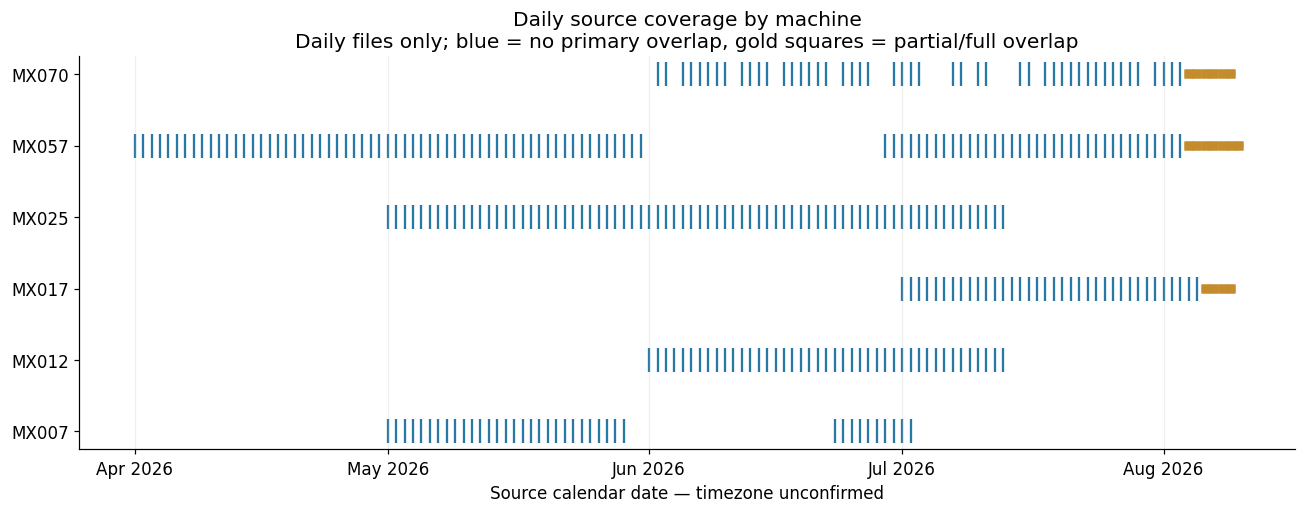

In [4]:
fig, ax = plt.subplots(figsize=(12,4.8))
for y, (machine,g) in enumerate(manifest[manifest['kind'].eq('DAILY_TELEMETRY') & manifest['date'].notna()].groupby('machine')):
    dates = pd.to_datetime(g['date'])
    overlap = g['overlap_rows'].fillna(0).gt(0)
    ax.scatter(dates[~overlap], np.full((~overlap).sum(),y), marker='|', s=260, color=BLUE)
    ax.scatter(dates[overlap], np.full(overlap.sum(),y), marker='s', s=25, color=GOLD)
ax.set_yticks(range(len(table)), ['MX'+m for m in table.index])
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_title('Daily source coverage by machine\nDaily files only; blue = no primary overlap, gold squares = partial/full overlap')
ax.set_xlabel('Source calendar date — timezone unconfirmed'); ax.grid(axis='x',alpha=.2)
fig.tight_layout(); fig.savefig(FIGURES/'01_coverage.png',bbox_inches='tight'); plt.show()


### 5. ข้อมูลที่เพิ่มจริงเทียบกับข้อมูลที่มีแล้ว
ความยาวแท่งเป็นจำนวนแถว ชุดนี้เพิ่มทั้งช่วงย้อนหลังของเครื่องเดิมและเครื่องที่ไม่อยู่ในชุดหลัก การเพิ่มจำนวนแถวไม่เท่ากับเพิ่ม fault labels

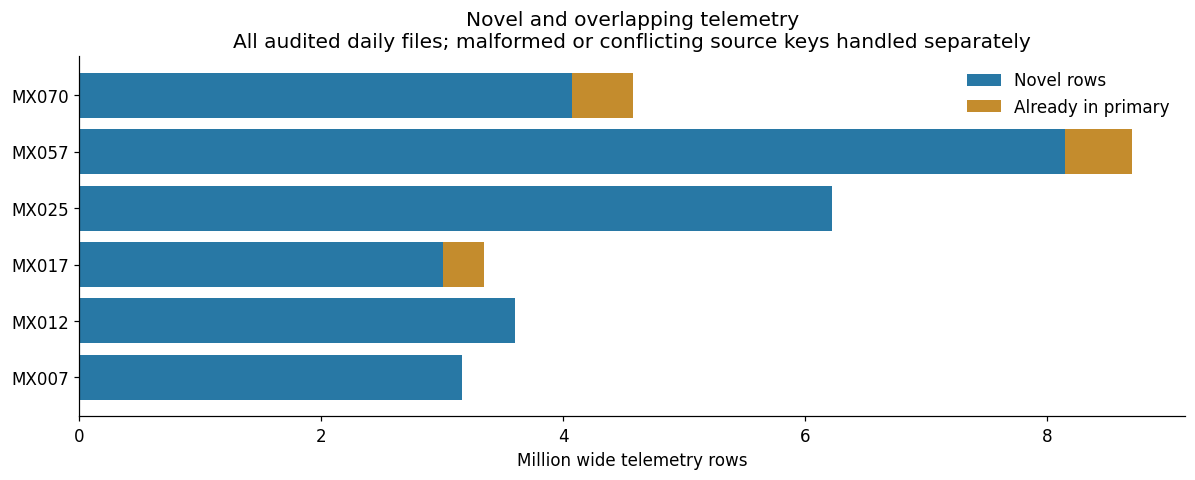

In [5]:
fig, ax = plt.subplots(figsize=(11,4.5))
y = np.arange(len(table))
ax.barh(y,table['novel_rows']/1e6,color=BLUE,label='Novel rows')
ax.barh(y,table['overlap_rows']/1e6,left=table['novel_rows']/1e6,color=GOLD,label='Already in primary')
ax.set_yticks(y,['MX'+m for m in table.index]); ax.set_xlim(left=0)
ax.set_xlabel('Million wide telemetry rows'); ax.legend(frameon=False)
ax.set_title('Novel and overlapping telemetry\nAll audited daily files; malformed or conflicting source keys handled separately')
fig.tight_layout(); fig.savefig(FIGURES/'02_novel_rows.png',bbox_inches='tight'); plt.show()


### 6. Hp_2nd ของแต่ละเครื่อง–โมดูล เมื่อ SV Off
แต่ละช่องคือ median ของ daily median ให้แต่ละวันมีน้ำหนักเท่ากัน จึงไม่ใช่ median ของวินาทีทั้งหมด ตัวเลขในวงเล็บคือจำนวนวันที่มี state-qualified samples ค่าเหล่านี้เป็น historical reference ที่ยังต้องตรวจ service epoch; ไม่ใช่ค่าปกติที่อนุมัติแล้ว

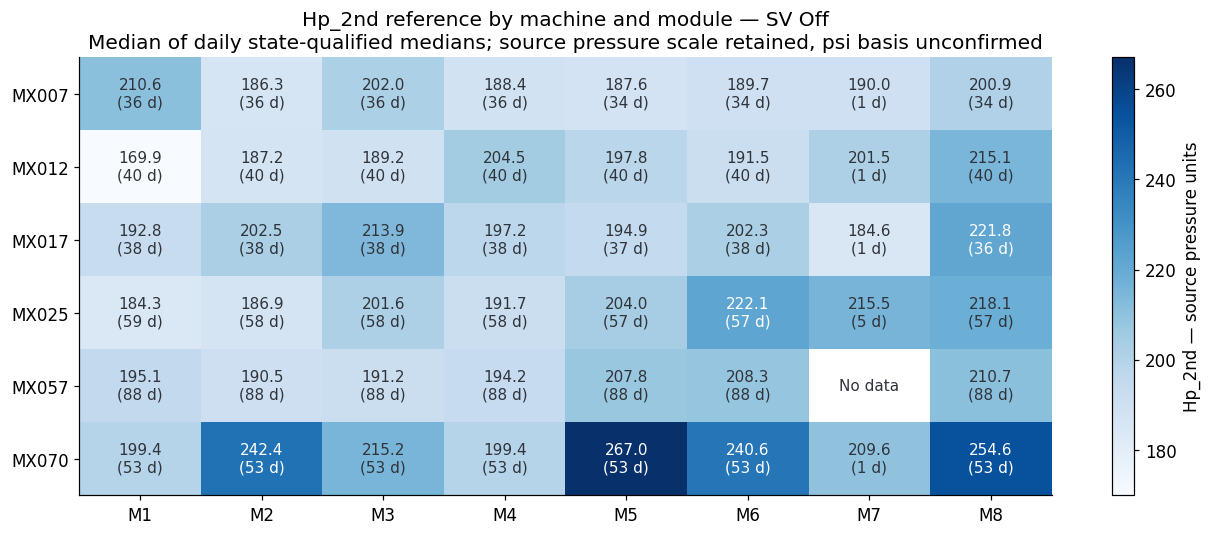

,machine,module,hp2,days
0,007,1,210.60,36
1,007,2,186.30,36
2,007,3,202.00,36
3,007,4,188.35,36
4,007,5,187.65,34
5,007,6,189.70,34
6,007,7,190.00,1
7,007,8,200.90,34
8,012,1,169.95,40
9,012,2,187.15,40


In [6]:
off = daily[daily.sv.eq('Off')]
profile = off.groupby(['machine','module']).agg(hp2=('hp2_median','median'), days=('date','nunique')).reset_index()
values = profile.pivot(index='machine',columns='module',values='hp2').reindex(columns=range(1,9))
counts = profile.pivot(index='machine',columns='module',values='days').reindex(columns=range(1,9))
fig,ax=plt.subplots(figsize=(12,5))
im=ax.imshow(np.ma.masked_invalid(values.to_numpy()),cmap='Blues',aspect='auto')
for i in range(len(values)):
    for j in range(8):
        v=values.iloc[i,j]
        ax.text(j,i, f'{v:.1f}\n({int(counts.iloc[i,j])} d)' if pd.notna(v) else 'No data',ha='center',va='center',fontsize=10,
                color='white' if pd.notna(v) and v>(np.nanmin(values.to_numpy())+np.nanmax(values.to_numpy()))/2 else INK)
ax.set_xticks(range(8),[f'M{i}' for i in range(1,9)]); ax.set_yticks(range(len(values)),['MX'+m for m in values.index])
ax.set_title('Hp_2nd reference by machine and module — SV Off\nMedian of daily state-qualified medians; source pressure scale retained, psi basis unconfirmed')
fig.colorbar(im,ax=ax,label='Hp_2nd — source pressure units'); fig.tight_layout()
fig.savefig(FIGURES/'03_hp2_reference.png',bbox_inches='tight'); plt.show()
display(profile)


### 7. ดูการเปลี่ยนตามเวลา ก่อนรวม baseline
กราฟแยก 8 โมดูลของแต่ละเครื่องและ SV ใช้สเกล pressure เดียวกัน ช่องว่างตามวันคงไว้ แถบ 180–230 psi แสดง qualified field reference ตาม README การเปลี่ยนระดับอาจมาจาก load, state, service, water context หรือ sensor จึงต้องผูกประวัติช่างก่อนอธิบายสาเหตุ

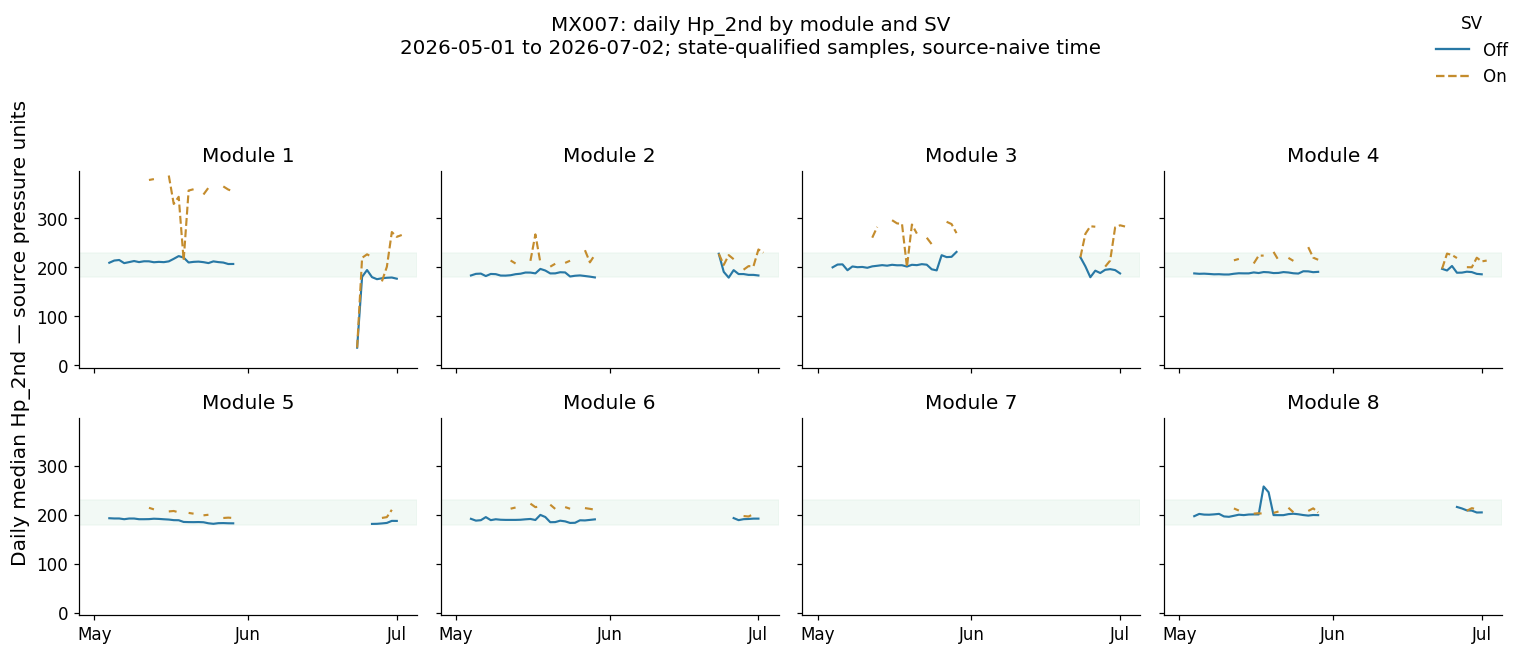

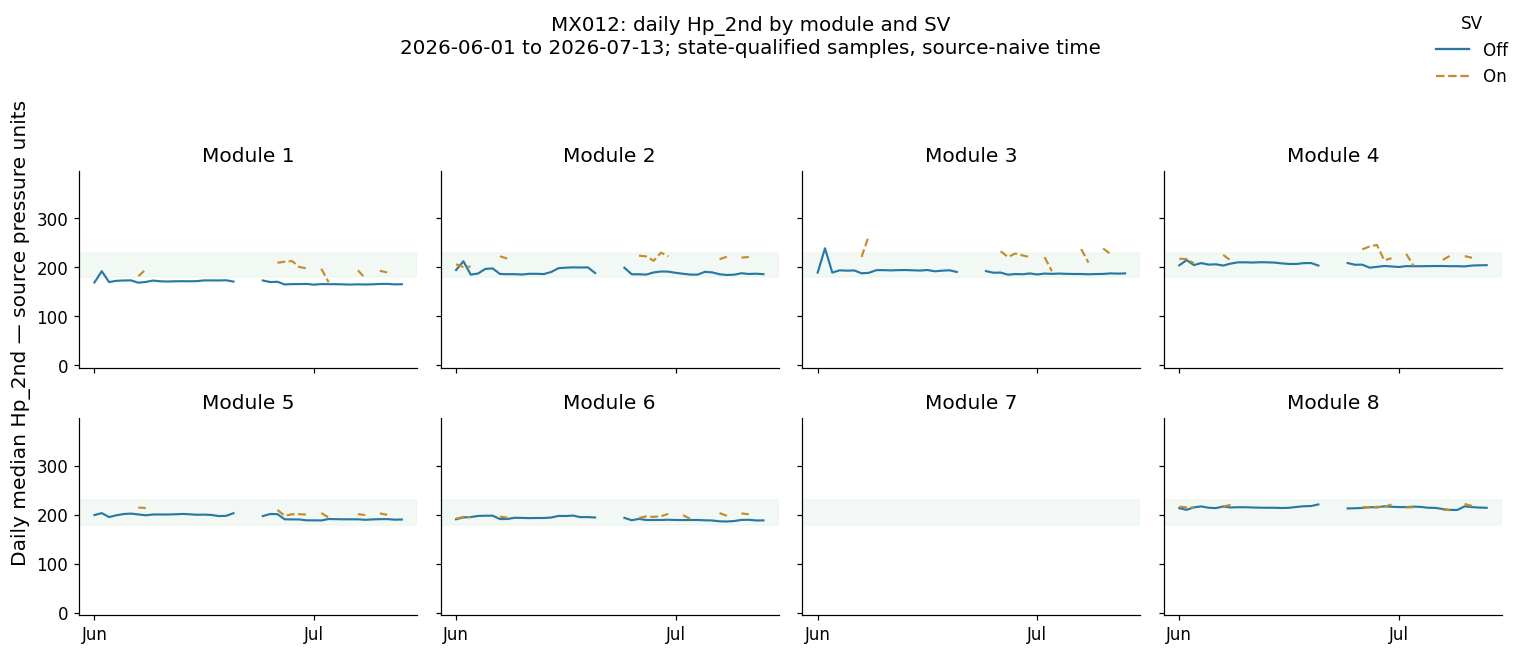

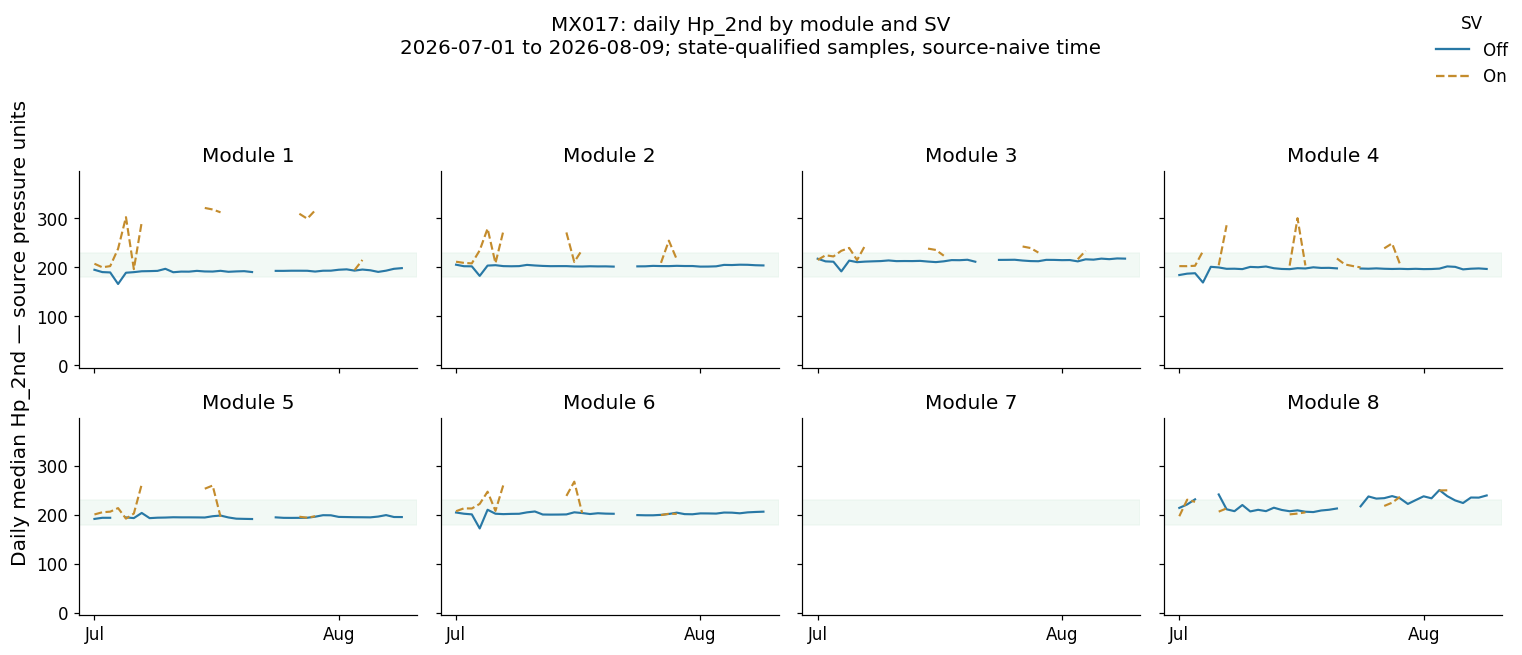

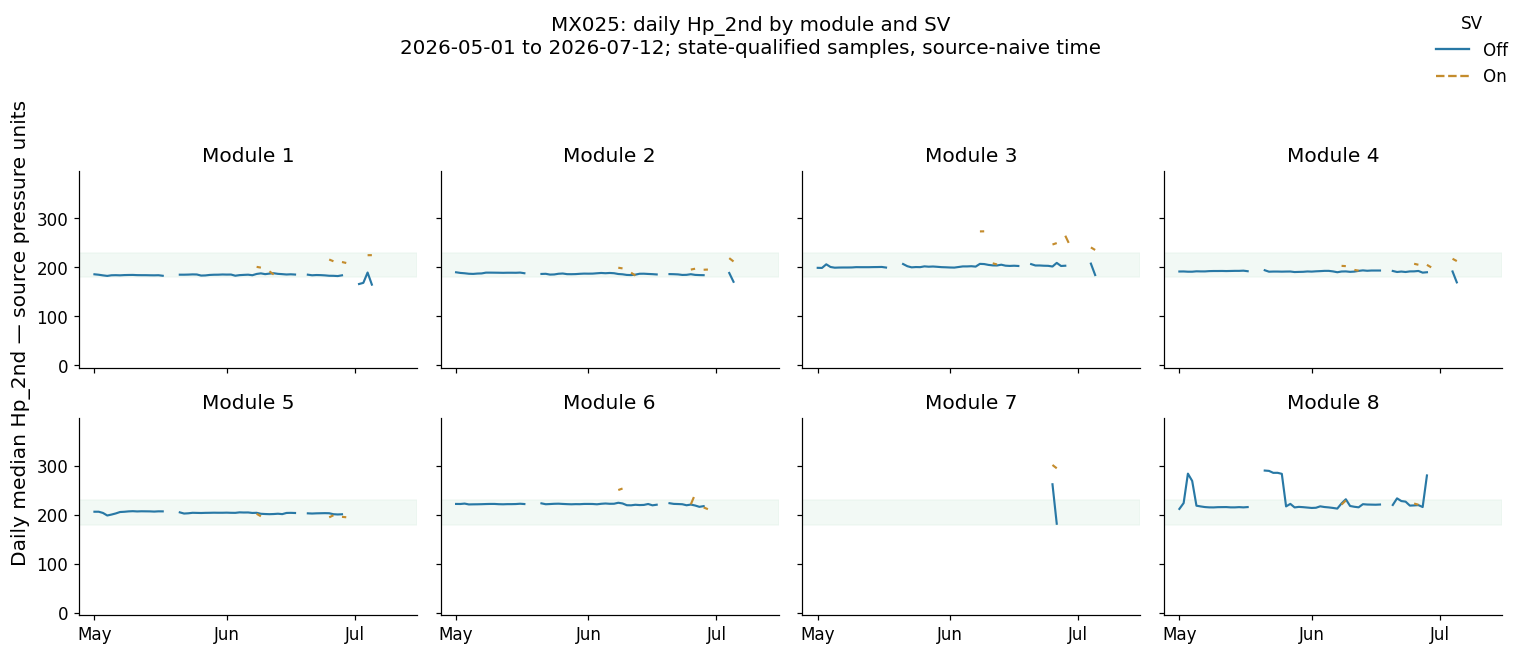

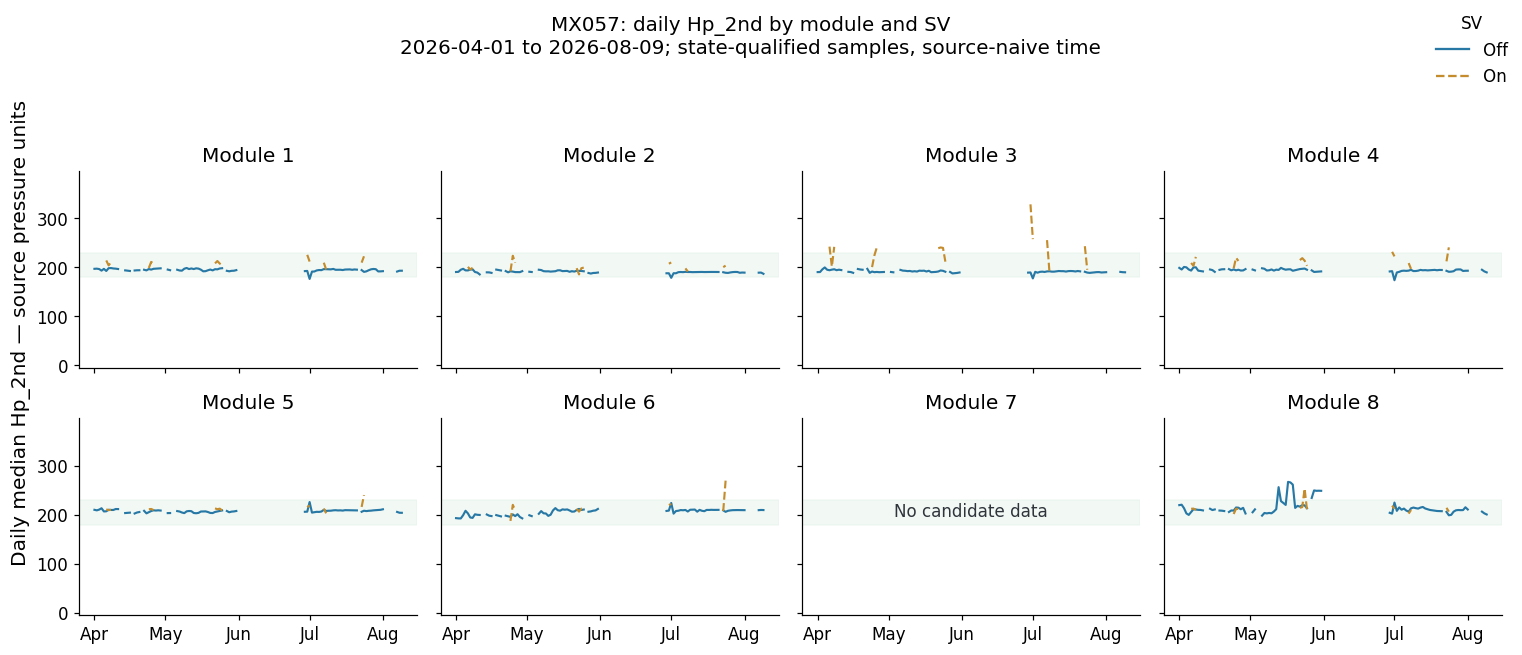

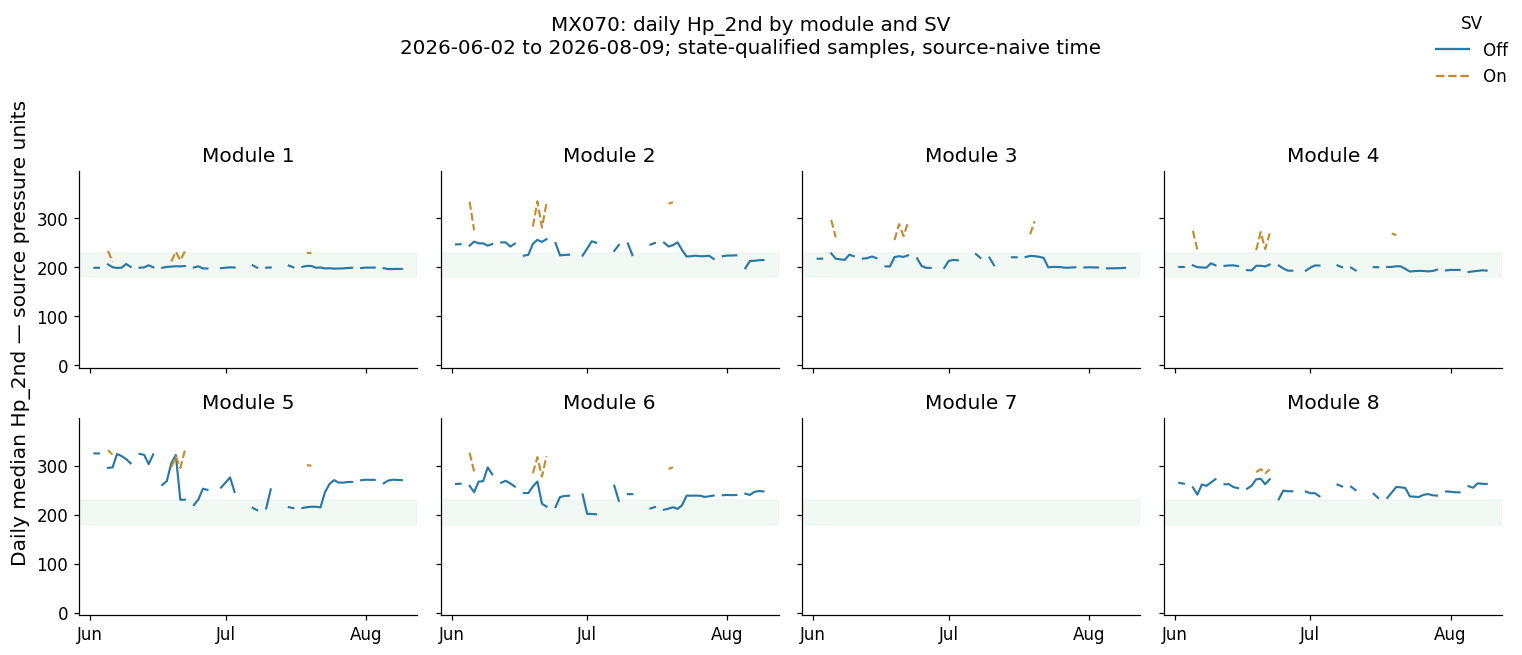

In [7]:
for machine in sorted(daily.machine.unique()):
    g=daily[daily.machine.eq(machine)]
    fig, axes=plt.subplots(2,4,figsize=(14,6),sharex=True,sharey=True)
    for module, ax in enumerate(axes.flat,1):
        if g[g.module.eq(module)].empty:
            ax.text(.5,.5,'No candidate data',transform=ax.transAxes,ha='center',color=INK)
        for sv,color,style in [('Off',BLUE,'-'),('On',GOLD,'--')]:
            s=g[g.module.eq(module)&g.sv.eq(sv)].sort_values('date').set_index('date')['hp2_median']
            if len(s):
                s=s.groupby(level=0).median().reindex(pd.date_range(g.date.min(),g.date.max(),freq='D'))
                ax.plot(s.index,s.values,color=color,linestyle=style,label=sv,linewidth=1.4)
        ax.axhspan(180,230,color='#DCEFE4',alpha=.35); ax.set_title(f'Module {module}')
        lo,hi=daily.hp2_median.min(),daily.hp2_median.max()
        ax.set_ylim(min(lo,180)-10,max(hi,230)+10); ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    handles=[Line2D([0],[0],color=BLUE,linestyle='-'),Line2D([0],[0],color=GOLD,linestyle='--')]
    fig.legend(handles,['Off','On'],loc='upper right',title='SV',frameon=False)
    fig.suptitle(f'MX{machine}: daily Hp_2nd by module and SV\n{g.date.min():%Y-%m-%d} to {g.date.max():%Y-%m-%d}; state-qualified samples, source-naive time',fontsize=13)
    fig.supylabel('Daily median Hp_2nd — source pressure units'); fig.tight_layout(rect=(0,0,1,.9))
    fig.savefig(FIGURES/f'04_MX{machine}_daily_hp2.png',bbox_inches='tight'); plt.show()


### 8. ความสัมพันธ์ Valve กับ Lp_2nd
ใช้ quality minute สำหรับ EDA ที่ผ่านความต่อเนื่องเพิ่ม 3 นาทีและ SV คงเดิม คำนวณ Spearman แยกเครื่อง–โมดูล–SV ตารางแนบจำนวนแถวและวันเสมอ ความสัมพันธ์ระดับนาทีนี้ยังไม่ใช่ lag response ระดับวินาทีหรือหลักฐานเหตุและผล

,machine,module,sv,minutes,days,spearman_valve_lp2
0,007,1,Off,37659,34,-0.126748
1,007,1,On,4850,19,-0.440436
2,007,2,Off,37713,34,0.273573
3,007,2,On,4837,19,0.320589
4,007,3,Off,37654,34,0.148348
...,...,...,...,...,...,...
82,070,5,On,839,15,0.390832
83,070,6,Off,65133,53,0.467928
84,070,6,On,836,15,0.443559
85,070,8,Off,65175,53,0.015101


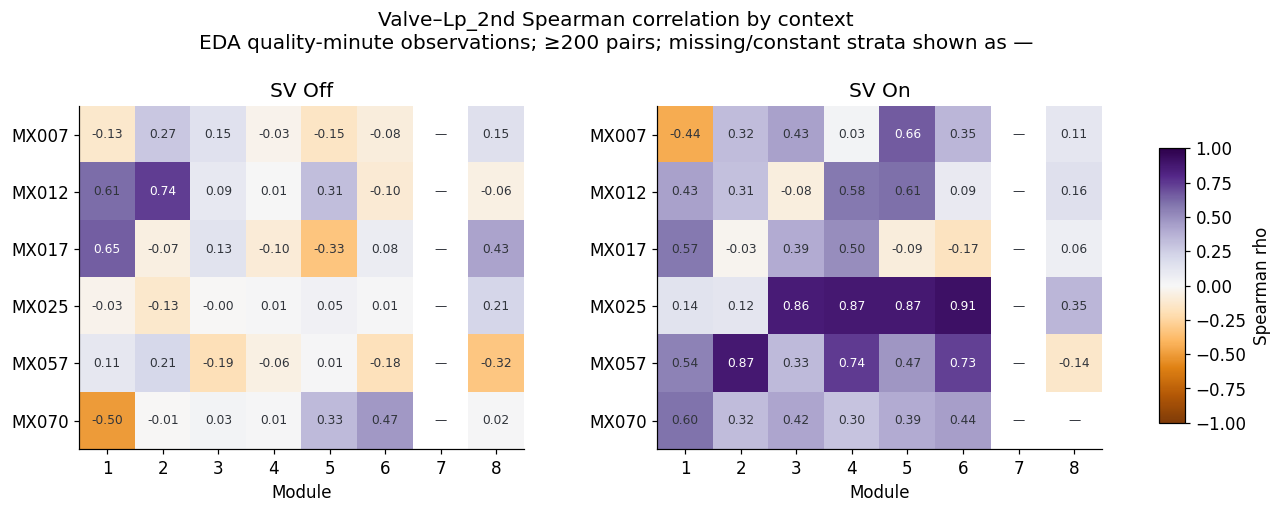

In [8]:
minute = pl.read_parquet(OUTPUT/'external_minute_module_state.parquet').to_pandas()
minute=minute.sort_values(['machine_number','module','minute'])
minute['machine_number']=minute['machine_number'].astype(str).str.zfill(3)
ok=minute['intake_quality_minute'].copy()
group=minute.groupby(['machine_number','module'],sort=False)
for lag in (1,2,3):
    ok &= group['intake_quality_minute'].shift(lag).eq(True)
    ok &= minute['minute'].sub(group['minute'].shift(lag)).eq(pd.Timedelta(minutes=lag))
    ok &= minute['sv'].eq(group['sv'].shift(lag))
rows=[]; sensor_pairs=[]
sensor_names=['hp1','lp1','hp2','lp2','valve','temphi','templo']
for (machine,module,sv),g in minute[ok].groupby(['machine_number','module','sv']):
    a=g[['valve','lp2']].dropna()
    rows.append({'machine':machine,'module':module,'sv':sv,'minutes':len(a),'days':g.minute.dt.date.nunique(),
                 'spearman_valve_lp2':a.valve.rank().corr(a.lp2.rank()) if len(a)>=200 and a.valve.nunique()>1 and a.lp2.nunique()>1 else np.nan})
    correlations=g[sensor_names].rank().corr() if len(g)>=200 else pd.DataFrame(np.nan,index=sensor_names,columns=sensor_names)
    for i,left in enumerate(sensor_names):
        for right in sensor_names[i+1:]:
            sensor_pairs.append({'machine':machine,'module':module,'sv':sv,'sensor_a':left,'sensor_b':right,
                                 'rho':correlations.loc[left,right],'minutes':len(g),'days':g.minute.dt.date.nunique()})
corr=pd.DataFrame(rows,columns=['machine','module','sv','minutes','days','spearman_valve_lp2']); corr.to_csv(OUTPUT/'minute_valve_lp2_correlations.csv',index=False)
pd.DataFrame(sensor_pairs,columns=['machine','module','sv','sensor_a','sensor_b','rho','minutes','days']).to_csv(OUTPUT/'all_sensor_pair_correlations.csv',index=False)
display(corr)
fig, axes=plt.subplots(1,2,figsize=(13,4.8))
for sv,ax in zip(['Off','On'],axes):
    p=corr[corr['sv'].eq(sv)].pivot(index='machine',columns='module',values='spearman_valve_lp2').reindex(index=sorted(daily.machine.unique()),columns=range(1,9))
    im=ax.imshow(np.ma.masked_invalid(p.to_numpy()),cmap='PuOr',vmin=-1,vmax=1,aspect='auto')
    for i in range(len(p)):
        for j in range(8):
            v=p.iloc[i,j]; ax.text(j,i,f'{v:.2f}' if pd.notna(v) else '—',ha='center',va='center',fontsize=8,color='white' if pd.notna(v) and abs(v)>.65 else INK)
    ax.set_xticks(range(8),range(1,9)); ax.set_yticks(range(len(p)),['MX'+m for m in p.index]); ax.set_xlabel('Module'); ax.set_title('SV '+sv)
fig.suptitle('Valve–Lp_2nd Spearman correlation by context\nEDA quality-minute observations; ≥200 pairs; missing/constant strata shown as —')
fig.subplots_adjust(top=.8,bottom=.15,wspace=.3,right=.84)
fig.colorbar(im,cax=fig.add_axes([.88,.2,.018,.52]),label='Spearman rho')
fig.savefig(FIGURES/'05_correlations.png',bbox_inches='tight'); plt.show()


### 9. เจาะความสัมพันธ์ของ sensor ทั้งเจ็ดในโมดูลที่เลือก
เปลี่ยน MACHINE, MODULE และ SV เพื่อดูโมดูลอื่น ตาราง `all_sensor_pair_correlations.csv` เก็บคู่ sensor ครบทุกกลุ่มที่มีข้อมูลแล้ว ค่าไม่แสดงเมื่อจำนวนต่ำกว่า 200 หรือ sensor คงที่

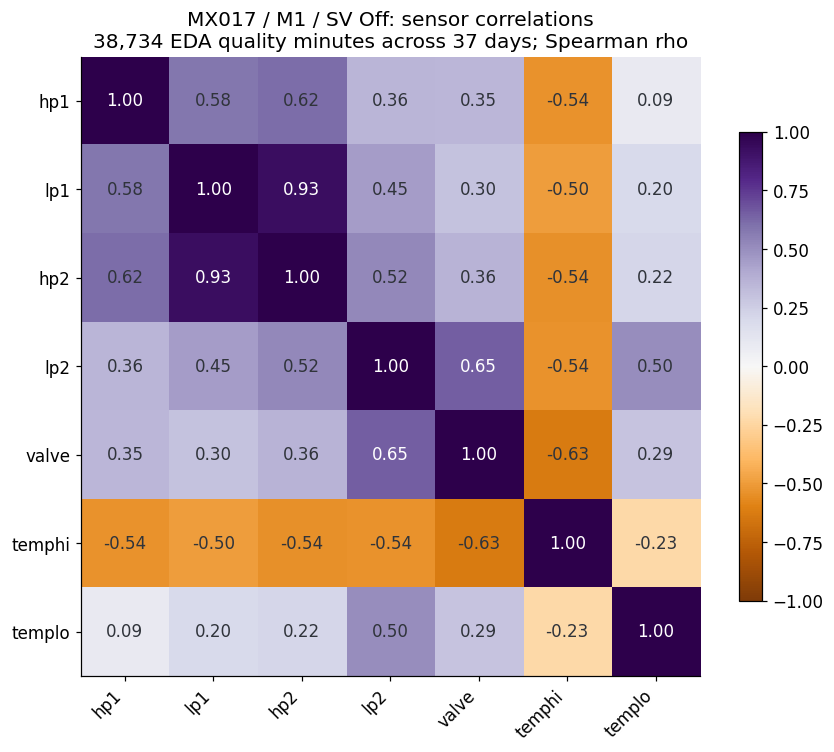

In [9]:
MACHINE, MODULE, SV = '017', 1, 'Off'
selected=minute[ok & minute.machine_number.eq(MACHINE) & minute.module.eq(MODULE) & minute.sv.eq(SV)]
matrix=selected[sensor_names].rank().corr() if len(selected)>=200 else pd.DataFrame(np.nan,index=sensor_names,columns=sensor_names)
fig,ax=plt.subplots(figsize=(8,7))
im=ax.imshow(np.ma.masked_invalid(matrix.to_numpy()),cmap='PuOr',vmin=-1,vmax=1)
for i in range(7):
    for j in range(7):
        value=matrix.iloc[i,j]
        ax.text(j,i,f'{value:.2f}' if pd.notna(value) else '—',ha='center',va='center',color='white' if pd.notna(value) and abs(value)>.65 else INK)
ax.set_xticks(range(7),sensor_names,rotation=45,ha='right'); ax.set_yticks(range(7),sensor_names)
ax.set_title(f'MX{MACHINE} / M{MODULE} / SV {SV}: sensor correlations\n{len(selected):,} EDA quality minutes across {selected.minute.dt.date.nunique()} days; Spearman rho')
fig.colorbar(im,ax=ax,shrink=.7); fig.tight_layout(); fig.savefig(FIGURES/'06_sensor_correlations.png',bbox_inches='tight'); plt.show()


### 10. QA ของการส่งต่อข้อมูล
ตรวจยอดจาก manifest กับ Parquet ที่แปลงจริง และตรวจ duplicate key ของข้อมูลใหม่ โดยไม่ fit หรือเปลี่ยนโมเดลเดิม

In [10]:
parts=[OUTPUT/p for p in manifest['canonical_partition'].dropna()]
canonical=pl.scan_parquet(parts)
total=canonical.select(pl.len()).collect().item()
duplicate_keys=canonical.group_by('machine_number','recorded_at').len().filter(pl.col('len')>1).select(pl.len()).collect().item()
qa={'canonical_count_matches_manifest':total==summary['novel_rows'],
    'unique_machine_timestamp':duplicate_keys==0,
    'no_training_enabled':not summary['train_enabled'],
    'all_daily_parsed':len(summary['errors'])==0,
    'overlap_equality_reconciled':summary['overlap_equal_rows']+summary['overlap_conflict_rows']+int(manifest.get('overlap_unresolved_rows',pd.Series(dtype=float)).fillna(0).sum())==summary['overlap_rows']}
display(pd.Series(qa,name='Passed').to_frame())
assert all(qa.values()), qa
(OUTPUT/'notebook_qa.json').write_text(json.dumps(qa,indent=2),encoding='utf-8')


,Passed
canonical_count_matches_manifest,True
unique_machine_timestamp,True
no_training_enabled,True
all_daily_parsed,True
overlap_equality_reconciled,True


180

## Takeaways

ข้อมูลเพิ่มถูกเชื่อมเข้าชั้นอ่านข้อมูลและ EDA แล้ว โดยมีไฟล์ต้นทางและ checksum ย้อนกลับได้ การนำไปฝึก ML ต่อใช้แผนดังนี้:

1. **MX017 / MX057 / MX070:** ใช้ช่วงก่อนชุดหลักศึกษาความเสถียรระยะยาวและเตรียม calibration candidate แยก service epoch ต้องประกาศ split รุ่นใหม่ก่อน fit
2. **MX007 / MX012 / MX025:** ใช้ศึกษาการย้ายไปเครื่องอื่นและทดสอบแบบย้อนหลัง แยกให้ชัดว่าเครื่องเหล่านี้ไม่อยู่ในชุดหลัก 19 เครื่อง แต่เคยปรากฏในโครงการ Data Analysis เดิม จึงไม่ถือเป็น blind holdout สำหรับทุกการทดลอง
3. **One-second analysis:** canonical ใหม่ยังเก็บ timestamp จริง จึงนำไปตรวจ coverage ของ opening/SV On และสร้าง window 30/120 วินาทีได้ ข้อมูลที่เพิ่มขึ้นยังไม่พิสูจน์ว่า coverage ของทุก state ผ่านแล้ว
4. **Auto-bootstrap:** เริ่มจาก EDA quality minutes แล้วเพิ่ม settling/service exclusion, uncertainty, shadow และ approval ตาม Phase 06
5. **ก่อน retrain:** ยืนยันหน่วยและ timezone, ผูก service/refill epoch, ประกาศ train/inner validation/calibration/outer test รุ่นใหม่ และให้ผล benchmark เดิมคงเป็นหลักฐานของ dataset รุ่นเดิม

ผล pressure และ correlation ในเล่มนี้ใช้ชี้จุดให้ตรวจต่อ การยืนยัน leak และการรับรอง baseline ต้องมีหลักฐานจากช่าง งาน server replay, deployment package และการทดลอง sequence ยังเป็นงานแยกที่ต้องทำต่อ
